In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score, roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

%matplotlib inline

In [3]:
df = pd.read_csv('data/online_shoppers_intention.csv')
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
df.dtypes

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object

In [5]:
df.columns = df.columns.str.lower()

In [6]:
for col in ['month', 'visitortype']:
    df[col] = df[col].str.lower()

In [7]:
# boolean columns

df['weekend'] = df['weekend'].astype(int)
df['revenue'] = df['revenue'].astype(int)

In [8]:
# numerical id

id_columns = ['operatingsystems', 'browser', 'region', 'traffictype']
for col in id_columns:
    df[col] = df[col].astype(str)

In [9]:
numerical = [
    'administrative', 'administrative_duration', 
    'informational', 'informational_duration', 
    'productrelated', 'productrelated_duration', 
    'bouncerates', 'exitrates', 'pagevalues', 'specialday'
]

In [10]:
categorical = [
    'month', 'operatingsystems', 'browser', 
    'region', 'traffictype', 'visitortype', 'weekend'
]

In [11]:
print("Dataset shape:", df.shape)
df.dtypes

Dataset shape: (12330, 18)


administrative               int64
administrative_duration    float64
informational                int64
informational_duration     float64
productrelated               int64
productrelated_duration    float64
bouncerates                float64
exitrates                  float64
pagevalues                 float64
specialday                 float64
month                       object
operatingsystems            object
browser                     object
region                      object
traffictype                 object
visitortype                 object
weekend                      int64
revenue                      int64
dtype: object

In [12]:
print("Missing values per column:")
print(df.isnull().sum())

df[numerical].describe().round(2)

Missing values per column:
administrative             0
administrative_duration    0
informational              0
informational_duration     0
productrelated             0
productrelated_duration    0
bouncerates                0
exitrates                  0
pagevalues                 0
specialday                 0
month                      0
operatingsystems           0
browser                    0
region                     0
traffictype                0
visitortype                0
weekend                    0
revenue                    0
dtype: int64


,administrative,administrative_duration,informational,informational_duration,productrelated,productrelated_duration,bouncerates,exitrates,pagevalues,specialday
count,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00
mean,2.32,80.82,0.50,34.47,31.73,1194.75,0.02,0.04,5.89,0.06
std,3.32,176.78,1.27,140.75,44.48,1913.67,0.05,0.05,18.57,0.20
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,7.00,184.14,0.00,0.01,0.00,0.00
50%,1.00,7.50,0.00,0.00,18.00,598.94,0.00,0.03,0.00,0.00
75%,4.00,93.26,0.00,0.00,38.00,1464.16,0.02,0.05,0.00,0.00
max,27.00,3398.75,24.00,2549.38,705.00,63973.52,0.20,0.20,361.76,1.00


revenue
0    0.845255
1    0.154745
Name: proportion, dtype: float64


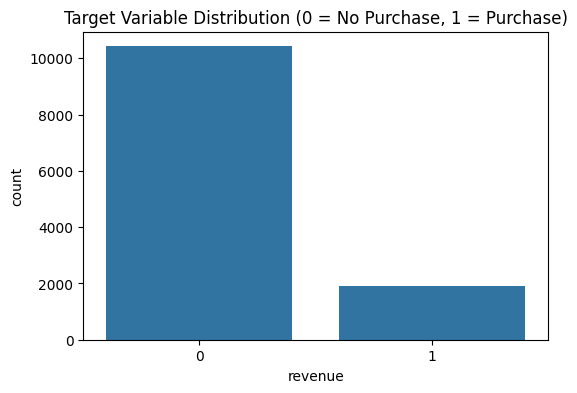

In [13]:
print(df['revenue'].value_counts(normalize=True))

plt.figure(figsize=(6, 4))
sns.countplot(x='revenue', data=df)
plt.title('Target Variable Distribution (0 = No Purchase, 1 = Purchase)')
plt.show()

## <span style="color:green">Train Validation Test Split</span>


In [14]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df['revenue'])
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42, stratify=df_full_train['revenue'])

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

y_train = df_train.revenue.values
y_val = df_val.revenue.values
y_test = df_test.revenue.values

del df_train['revenue']
del df_val['revenue']
del df_test['revenue']

## <span style="color:green">Correlation</span>


Numerical Correlation with Revenue:
 pagevalues                 0.503271
exitrates                  0.212674
productrelated             0.155596
bouncerates                0.154210
productrelated_duration    0.145974
administrative             0.142691
administrative_duration    0.099236
informational              0.097372
specialday                 0.087851
informational_duration     0.068662
dtype: float64


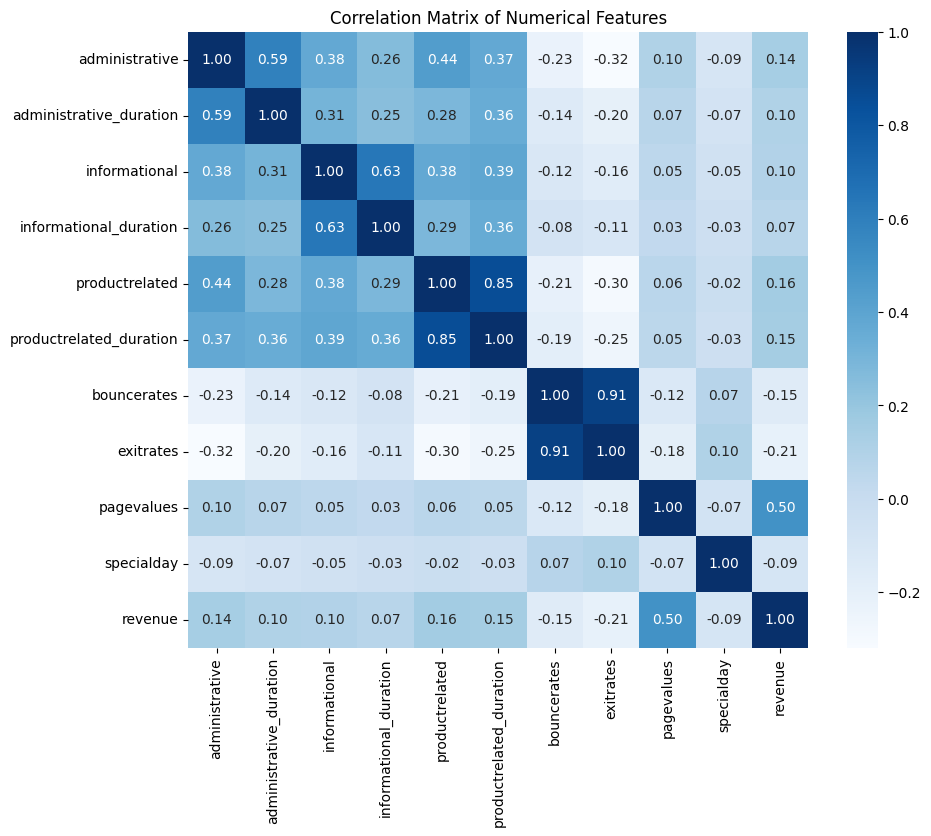

In [15]:
corr_with_target = df_full_train[numerical].corrwith(df_full_train.revenue).abs().sort_values(ascending=False)
print("Numerical Correlation with Revenue:\n", corr_with_target)

plt.figure(figsize=(10, 8))
sns.heatmap(df_full_train[numerical + ['revenue']].corr(), annot=True, fmt='.2f', cmap='Blues')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

## <span style="color:green">Mutual Information</span>


In [16]:
def mutual_info_revenue_score(series):
    return mutual_info_score(series, df_full_train.revenue)

mi = df_full_train[categorical].apply(mutual_info_revenue_score)
mi = mi.sort_values(ascending=False)
print("Mutual Information Scores:\n", mi.round(4))

Mutual Information Scores:
 traffictype         0.0167
month               0.0147
visitortype         0.0047
operatingsystems    0.0033
browser             0.0016
weekend             0.0006
region              0.0003
dtype: float64


## <span style="color:green">One Hot Encoding</span>

In [17]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

## <span style="color:green">Logistic regression</span>

In [18]:
scores_lr = []

for c in [0.001, 0.01, 0.1, 1, 10, 100]:
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=1)
    model.fit(X_train, y_train)
    
    y_pred = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    scores_lr.append((c, round(auc, 4)))

df_scores_lr = pd.DataFrame(scores_lr, columns=['C', 'val_auc'])
print(df_scores_lr)

         C  val_auc
0    0.001   0.8338
1    0.010   0.9053
2    0.100   0.8980
3    1.000   0.8944
4   10.000   0.8953
5  100.000   0.8937


## <span style="color:green">Decision Tree Validation</span>

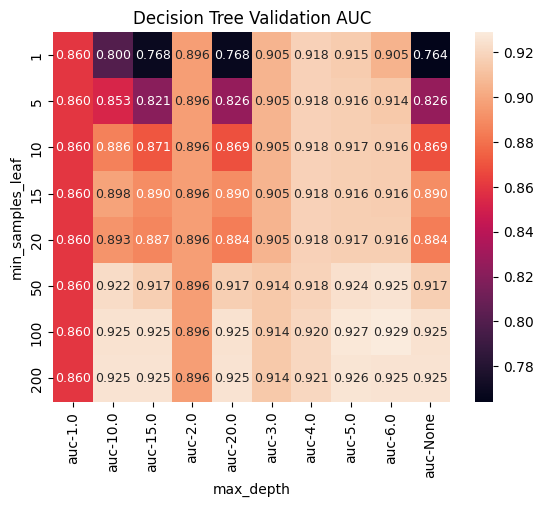

,max_depth,min_samples_leaf,auc
46,6.0,100,0.928886
38,5.0,100,0.927084
39,5.0,200,0.925919
47,6.0,200,0.925442
45,6.0,50,0.925235


In [19]:
scores_dt = []

for depth in [1, 2, 3, 4, 5, 6, 10, 15, 20, None]:
    for s in [1, 5, 10, 15, 20, 50, 100, 200]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s, random_state=1)
        dt.fit(X_train, y_train)
        
        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores_dt.append((depth, s, auc))

df_scores_dt = pd.DataFrame(scores_dt, columns=['max_depth', 'min_samples_leaf', 'auc'])

df_scores_dt['max_depth'] = df_scores_dt['max_depth'].fillna('None').astype(str)

df_scores_dt_pivot = df_scores_dt.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
sns.heatmap(df_scores_dt_pivot, annot=True, fmt='.3f', annot_kws={'size': 9})
plt.title('Decision Tree Validation AUC')
plt.xlabel('max_depth')
plt.ylabel('min_samples_leaf')
plt.show()

df_scores_dt.sort_values(by='auc', ascending=False).head(5)

## <span style="color:green">Random Forest</span>

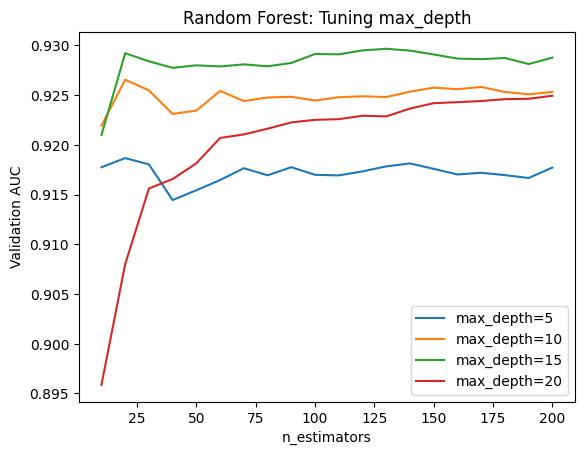

In [20]:
scores_rf = []

for d in [5, 10, 15, 20]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores_rf.append((d, n, auc))

df_scores_rf = pd.DataFrame(scores_rf, columns=['max_depth', 'n_estimators', 'auc'])

for d in [5, 10, 15, 20]:
    df_subset = df_scores_rf[df_scores_rf.max_depth == d]
    plt.plot(df_subset.n_estimators, df_subset.auc, label=f'max_depth={d}')

plt.legend()
plt.xlabel('n_estimators')
plt.ylabel('Validation AUC')
plt.title('Random Forest: Tuning max_depth')
plt.show()

Auto-selected Best Random Forest max_depth: 15


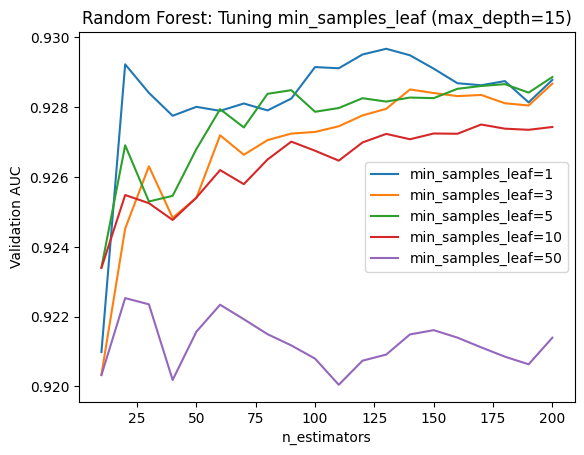

,min_samples_leaf,n_estimators,auc
12,1,130,0.929664
11,1,120,0.929500
13,1,140,0.929478
1,1,20,0.929218
9,1,100,0.929140


In [21]:
best_depth = int(df_scores_rf.sort_values(by='auc', ascending=False).iloc[0]['max_depth'])
print("Auto-selected Best Random Forest max_depth:", best_depth)
scores_rf_leaf = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(
            n_estimators=n,
            max_depth=best_depth,
            min_samples_leaf=s,
            random_state=1,
            n_jobs=-1
        )
        rf.fit(X_train, y_train)
        
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores_rf_leaf.append((s, n, auc))

df_scores_rf_leaf = pd.DataFrame(scores_rf_leaf, columns=['min_samples_leaf', 'n_estimators', 'auc'])

for s in [1, 3, 5, 10, 50]:
    df_subset = df_scores_rf_leaf[df_scores_rf_leaf.min_samples_leaf == s]
    plt.plot(df_subset.n_estimators, df_subset.auc, label=f'min_samples_leaf={s}')

plt.legend()
plt.xlabel('n_estimators')
plt.ylabel('Validation AUC')
plt.title('Random Forest: Tuning min_samples_leaf (max_depth=15)')
plt.show()

df_scores_rf_leaf.sort_values(by='auc', ascending=False).head(5)

## <span style="color:green">XGBoost</span>

In [22]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

watchlist = [(dtrain, 'train'), (dval, 'val')]

In [23]:
xgb_scores = []

for eta in [0.01, 0.05, 0.1, 0.3]:
    for max_depth in [3, 4, 6, 10]:
        for min_child_weight in [1, 5, 10]:
            xgb_params = {
                'eta': eta,
                'max_depth': max_depth,
                'min_child_weight': min_child_weight,
                'objective': 'binary:logistic',
                'eval_metric': 'auc',
                'nthread': 8,
                'seed': 1,
                'verbosity': 0,
            }
            model = xgb.train(
                xgb_params,
                dtrain,
                num_boost_round=300,
                evals=watchlist,
                early_stopping_rounds=20,
                verbose_eval=False
            )
            
            best_iter = model.best_iteration
            y_pred = model.predict(dval, iteration_range=(0, best_iter + 1))
            auc = roc_auc_score(y_val, y_pred)
            xgb_scores.append((eta, max_depth, min_child_weight, best_iter + 1, auc))

df_xgb_scores = pd.DataFrame(
    xgb_scores, columns=['eta', 'max_depth', 'min_child_weight', 'best_num_trees', 'val_auc']
)
df_xgb_scores.sort_values(by='val_auc', ascending=False).head(10)

,eta,max_depth,min_child_weight,best_num_trees,val_auc
31,0.10,6,5,30,0.936764
11,0.01,10,10,211,0.936390
19,0.05,6,5,54,0.936175
16,0.05,4,5,56,0.936158
44,0.30,6,10,10,0.936039
15,0.05,4,1,65,0.936006
20,0.05,6,10,55,0.935938
29,0.10,4,10,24,0.935928
32,0.10,6,10,27,0.935820
5,0.01,4,10,227,0.935723


In [25]:
best_row = df_xgb_scores.sort_values(by='val_auc', ascending=False).iloc[0]
best_eta = float(best_row['eta'])
best_max_depth = int(best_row['max_depth'])
best_min_child_weight = int(best_row['min_child_weight'])
best_num_trees = int(best_row['best_num_trees'])

print(f"Auto-selected Best XGBoost Parameters:")
print(f" - eta: {best_eta}")
print(f" - max_depth: {best_max_depth}")
print(f" - min_child_weight: {best_min_child_weight}")
print(f" - num_boost_round: {best_num_trees}")
print(f" - Validation AUC: {best_row['val_auc']:.4f}\n")

df_full_train_clean = df_full_train.copy()
if 'revenue' in df_full_train_clean.columns:
    y_full_train = df_full_train_clean.revenue.values
    del df_full_train_clean['revenue']

dicts_full_train = df_full_train_clean[categorical + numerical].to_dict(orient='records')
X_full_train = dv.fit_transform(dicts_full_train)

dicts_test = df_test[categorical + numerical].to_dict(orient='records')
X_test = dv.transform(dicts_test)

features_full = list(dv.get_feature_names_out())
dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features_full)
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=features_full)

final_xgb_params = {
    'eta': best_eta,
    'max_depth': best_max_depth,
    'min_child_weight': best_min_child_weight,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 1,
    'seed': 1,
    'verbosity': 1,
}

final_model = xgb.train(final_xgb_params, dfulltrain, num_boost_round=best_num_trees)
y_pred_test = final_model.predict(dtest)
print("Final Test ROC AUC:", round(roc_auc_score(y_test, y_pred_test), 4))

Auto-selected Best XGBoost Parameters:
 - eta: 0.1
 - max_depth: 6
 - min_child_weight: 5
 - num_boost_round: 30
 - Validation AUC: 0.9368

Final Test ROC AUC: 0.9309
